## Polynomial Regression

Linear Regression can only capture linear relationships.
When data has a curved pattern, we need Polynomial Regression.

### How It Works
Polynomial Regression adds new features by raising existing 
features to higher powers:
- degree=2: adds X²
- degree=3: adds X², X³  
- degree=n: adds X², X³... Xⁿ

The model is still Linear Regression — just on transformed features.

### The Degree Problem
| Degree | Behavior |
|---|---|
| Too low | Underfitting — misses the pattern |
| Just right | Captures true relationship |
| Too high | Overfitting — memorizes noise |

### Train vs Test R²
- Train R² always increases with degree
- Test R² peaks at optimal degree then drops
- Always use test R² to select degree — never train R²

### Key Rule
Use cross validation to find the optimal degree —
never select degree based on training performance alone.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

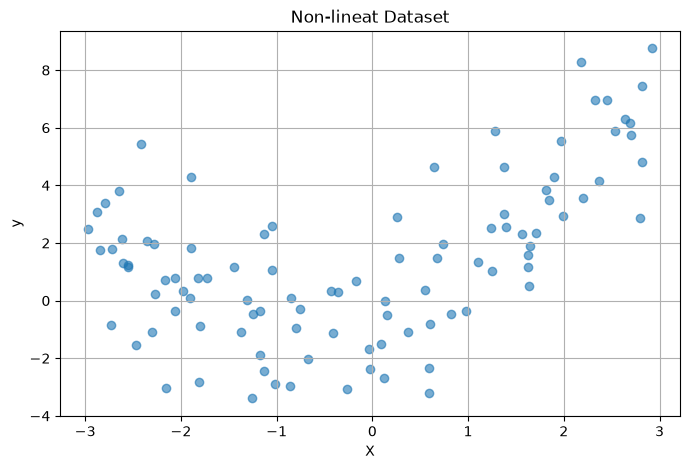

In [2]:
np.random.seed(42)
m = 100

X_poly = 6 * np.random.rand(m, 1) - 3 # values between -3 and 3
y_poly = 0.5 * X_poly**2 + X_poly + 2 * np.random.randn(m,1) #(noise)

plt.figure(figsize=(8,5))
plt.scatter(X_poly, y_poly, alpha=0.6)
plt.xlabel('X')
plt.ylabel('y')
plt.title("Non-lineat Dataset")
plt.grid(True)
plt.show()

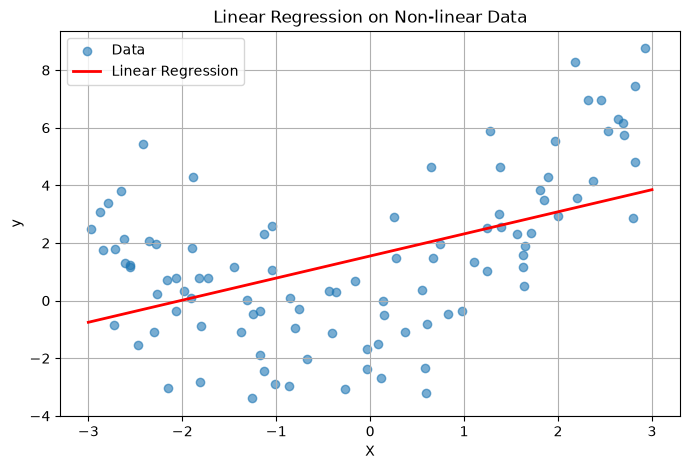

Linear Regression R²: 0.2393
Linear Regression MSE: 5.8995


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Plain Linear Regression
lr = LinearRegression()
lr.fit(X_poly, y_poly)

# Plot
X_range = np.linspace(-3, 3, 100).reshape(-1, 1)
y_lr_pred = lr.predict(X_range)

plt.figure(figsize=(8,5))
plt.scatter(X_poly, y_poly, alpha=0.6, label='Data')
plt.plot(X_range, y_lr_pred, 'r-', linewidth=2, label='Linear Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression on Non-linear Data')
plt.legend()
plt.grid(True)
plt.show()

print(f"Linear Regression R²: {lr.score(X_poly, y_poly):.4f}")
print(f"Linear Regression MSE: {mean_squared_error(y_poly, lr.predict(X_poly)):.4f}")



In [4]:
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly_transformed = poly_features.fit_transform(X_poly)

print("Original X shape:", X_poly.shape)
print("Transformed X shape:", X_poly_transformed.shape)
print("New features:", poly_features.get_feature_names_out(['X']))
print("\nFirst 3 rows of transformed X:")
print(X_poly_transformed[:3])


Original X shape: (100, 1)
Transformed X shape: (100, 2)
New features: ['X' 'X^2']

First 3 rows of transformed X:
[[-0.75275929  0.56664654]
 [ 2.70428584  7.3131619 ]
 [ 1.39196365  1.93756281]]


Coefficients: [0.86733786 0.62912527]
Intercept: -0.4373
Polynomial R-square: 0.5991
Polynomial MSE: 3.1088


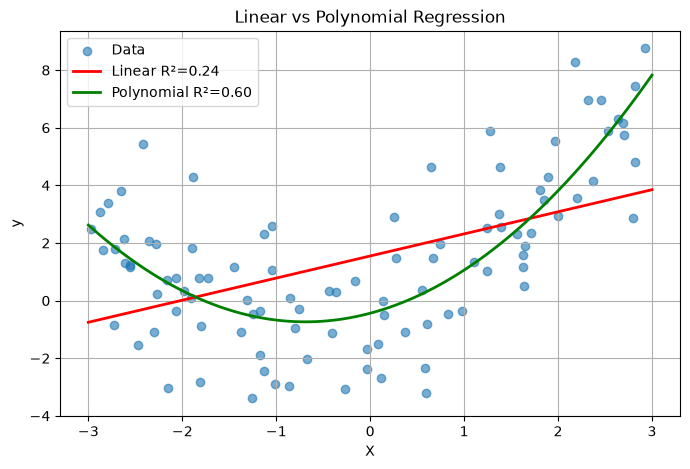

In [5]:
poly_lr = LinearRegression()
poly_lr.fit(X_poly_transformed, y_poly)

print(f"Coefficients: {poly_lr.coef_.flatten()}")
print(f"Intercept: {poly_lr.intercept_[0]:.4f}")
print(f"Polynomial R-square: {poly_lr.score(X_poly_transformed, y_poly):.4f}")
print(f"Polynomial MSE: {mean_squared_error(y_poly, poly_lr.predict(X_poly_transformed)):.4f}")

# Plot
X_range = np.linspace(-3, 3, 100).reshape(-1, 1)
X_range_poly = poly_features.transform(X_range)
y_poly_pred = poly_lr.predict(X_range_poly)

plt.figure(figsize=(8, 5))
plt.scatter(X_poly, y_poly, alpha=0.6, label='Data')
plt.plot(X_range, y_lr_pred, 'r-', linewidth=2, label=f'Linear R²={lr.score(X_poly, y_poly):.2f}')
plt.plot(X_range, y_poly_pred, 'g-', linewidth=2, label=f'Polynomial R²={poly_lr.score(X_poly_transformed, y_poly):.2f}')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear vs Polynomial Regression')
plt.legend()
plt.grid(True)
plt.show()

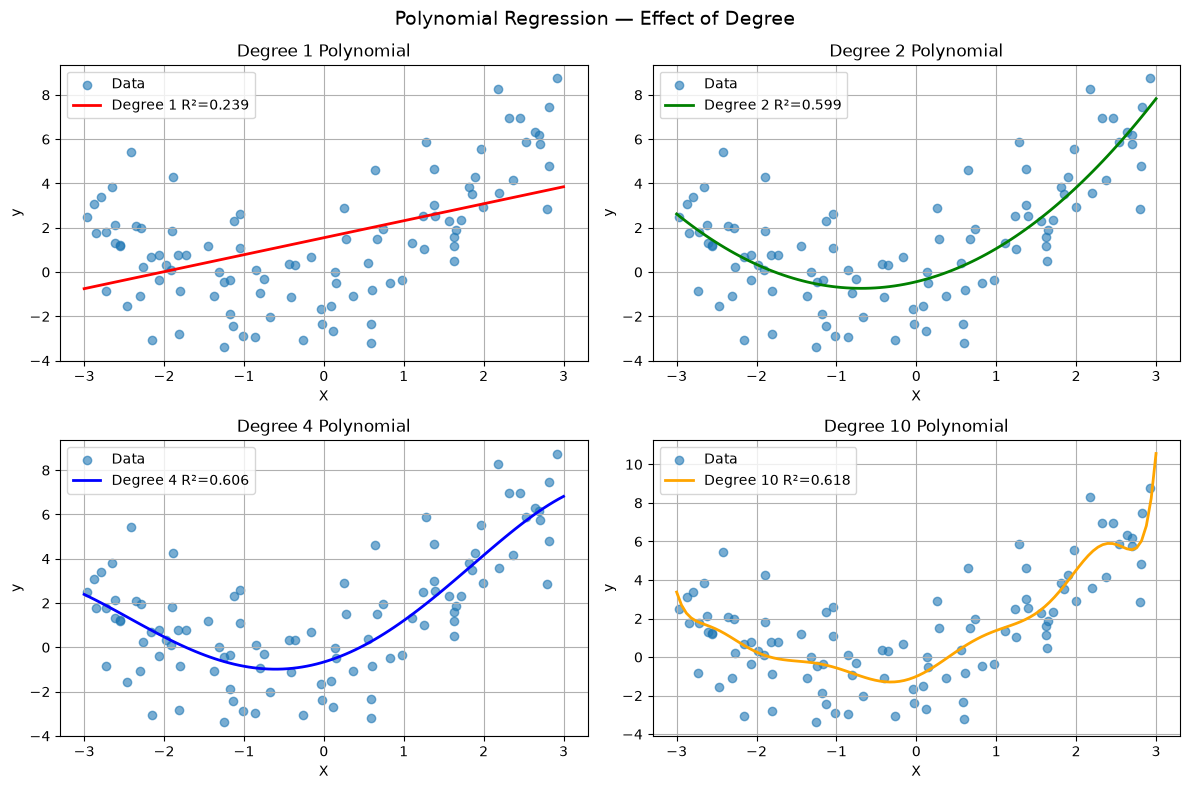

In [6]:
degrees = [1, 2, 4, 10]
colors = ['red', 'green', 'blue', 'orange']

plt.figure(figsize=(12, 8))

for idx, degree in enumerate(degrees):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_transformed = poly.fit_transform(X_poly)
    
    model = LinearRegression()
    model.fit(X_transformed, y_poly)
    
    X_range_transformed = poly.transform(X_range)
    y_pred = model.predict(X_range_transformed)
    
    r2 = model.score(X_transformed, y_poly)
    
    plt.subplot(2, 2, idx + 1)
    plt.scatter(X_poly, y_poly, alpha=0.6, label='Data')
    plt.plot(X_range, y_pred, color=colors[idx], linewidth=2, 
             label=f'Degree {degree} R²={r2:.3f}')
    # plt.ylim(-5, 10)
    plt.xlabel('X')
    plt.ylabel('y')
    plt.title(f'Degree {degree} Polynomial')
    plt.legend()
    plt.grid(True)

plt.suptitle('Polynomial Regression — Effect of Degree', fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=42
)

print(f"{'Degree':<10} {'Train R²':>10} {'Test R²':>10}")
print("-" * 32)

for degree in [1, 2, 4, 6, 10, 15, 20]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    
    X_train_transformed = poly.fit_transform(X_train_p)
    X_test_transformed = poly.transform(X_test_p)
    
    model = LinearRegression()
    model.fit(X_train_transformed, y_train_p)
    
    train_r2 = model.score(X_train_transformed, y_train_p)
    test_r2 = model.score(X_test_transformed, y_test_p)
    
    print(f"{degree:<10} {train_r2:>10.4f} {test_r2:>10.4f}")

Degree       Train R²    Test R²
--------------------------------
1              0.2370     0.1763
2              0.5985     0.5667
4              0.6119     0.5304
6              0.6144     0.5210
10             0.6203     0.5494
15             0.5544     0.5874
20             0.4518     0.4344


In [8]:
class RidgeRegressionGD:
    def __init__(self, learning_rate=0.01, epochs=1000, alpha=1.0, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n, 1) * 0.01
        self.bias = np.zeros((1,1))

        if self.verbose:
            print("Ridge Regression Training:")
            print(f" Alpha (regularization): {self.alpha}")
            print(f" X shape: {X.shape}")
            print("-" * 50)

        for epoch in range(self.epochs):

            # Forward pass
            predictions = X.dot(self.weights) + self.bias

            # Errors
            errors = predictions - y

            # Key difference from Linear Regression
            # Gradients with L2 penalty
            # The extra term in dW, (α/m)*weights is the Ridge penalty gradient
            dW = (1/m) * X.T.dot(errors) + (self.alpha/m) * self.weights
            db = (1/m) * np.sum(errors) # bias is not regularized

            # Update parameters
            self.weights = self.weights - self.learning_rate * dW
            self.bias = self.bias - self.learning_rate * db

            # Cost with Ridge  penalty
            mse = (1/(2*m)) * np.sum(errors ** 2)
            ridge_penalty = (self.alpha/(2*m)) * np.sum(self.weights**2)
            cost = mse + ridge_penalty
            self.cost_history.append(cost)

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"\nEpoch {epoch:4d}/{self.epochs}")
                print(f"Cost: {cost:.6f}")
                print("MSE: {mse:.6f}")
                print(f"Ridge Penalty: {ridge_penalty:.6f}")


        if self.verbose:
            print("-" * 50)
            print(f"Final weights: {self.weights.flatten().round(4)}")
            print(f"Final bias: {self.bias.flatten()[0]:.4f}")

        return self

    def predict(self, X):
        return X.dot(self.weights) + self.bias

    def score(self, X, y):
        predictions = self.predict(X)
        ss_res = np.sum((y - predictions) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_res / ss_tot)

In [9]:
# create degree 10 polynomial features
poly = PolynomialFeatures(degree=10, include_bias=False)
X_train_poly = poly.fit_transform(X_train_p)
X_test_poly = poly.transform(X_test_p)

# Scale - important for regularization
scaler = StandardScaler()
X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

# Compare different alpha values
alphas = [0, 1, 10, 100]

print(f"{'Alpha':<10} {'Train R²':>10} {'Test R²':>10}")
print("-" * 32)

for alpha in alphas:
    ridge = RidgeRegressionGD(
        learning_rate=0.01,
        epochs=1000,
        alpha=alpha,
        verbose=False
    )
    ridge.fit(X_train_poly_scaled, y_train_p)
    
    train_r2 = ridge.score(X_train_poly_scaled, y_train_p)
    test_r2 = ridge.score(X_test_poly_scaled, y_test_p)
    
    print(f"{alpha:<10} {train_r2:>10.4f} {test_r2:>10.4f}")

Alpha        Train R²    Test R²
--------------------------------
0              0.6026     0.5740
1              0.6013     0.5770
10             0.5818     0.5765
100            0.4688     0.4219


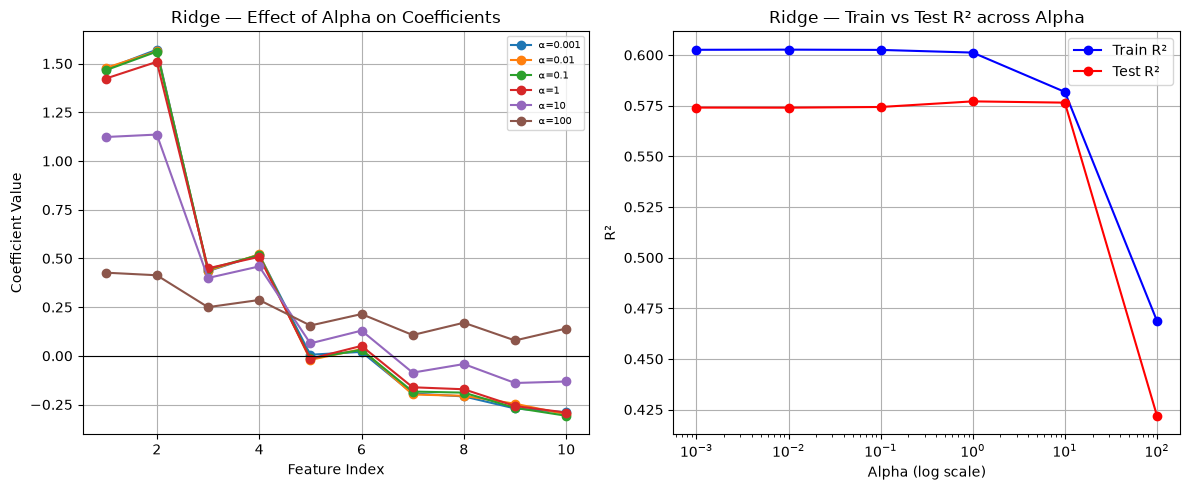

In [10]:
# Plot 1 — Effect of alpha on coefficients
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
all_weights = []

for alpha in alphas:
    ridge = RidgeRegressionGD(
        learning_rate=0.01,
        epochs=1000,
        alpha=alpha,
        verbose=False
    )
    ridge.fit(X_train_poly_scaled, y_train_p)
    all_weights.append(ridge.weights.flatten())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for i, weights in enumerate(all_weights):
    plt.plot(range(1, 11), weights, marker='o', label=f'α={alphas[i]}')
plt.xlabel('Feature Index')
plt.ylabel('Coefficient Value')
plt.title('Ridge — Effect of Alpha on Coefficients')
plt.legend(fontsize=7)
plt.grid(True)
plt.axhline(y=0, color='black', linewidth=0.8)

# Plot 2 — Train vs Test R² across alphas
train_r2s = []
test_r2s = []

for alpha in alphas:
    ridge = RidgeRegressionGD(
        learning_rate=0.01,
        epochs=1000,
        alpha=alpha,
        verbose=False
    )
    ridge.fit(X_train_poly_scaled, y_train_p)
    train_r2s.append(ridge.score(X_train_poly_scaled, y_train_p))
    test_r2s.append(ridge.score(X_test_poly_scaled, y_test_p))

plt.subplot(1, 2, 2)
plt.semilogx(alphas, train_r2s, 'b-o', label='Train R²')
plt.semilogx(alphas, test_r2s, 'r-o', label='Test R²')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R²')
plt.title('Ridge — Train vs Test R² across Alpha')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
class LassoRegressionGD:
    def __init__(self, learning_rate=0.01, epochs=1000, alpha=1.0, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.alpha = alpha
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n,1) * 0.01
        self.bias = np.zeros((1,1))

        if self.verbose:
            print(f"Lasso Regression Training:")
            print(f"  Alpha (regularization): {self.alpha}")
            print(f"  X shape: {X.shape}")
            print("-" * 50)

        for epoch in range(self.epochs):

            predictions = X.dot(self.weights) + self.bias

            errors = predictions - y

            # dW = (1/m) * X.T.dot(errors) + (self.alpha/m) * np.sign(self.weights)
            # db = (1/m) * np.sum(errors)

            # Step 1 - gadient step (no Lasso penalty yet)
            weights_temp = self.weights - self.learning_rate * ((1/m) * X.T.dot(errors))

            # Step 2 - soft thresholding (apply Lasso penalty)
            threshold = self.learning_rate * self.alpha / m
            self.weights = np.sign(weights_temp) * np.maximum(np.abs(weights_temp) - threshold, 0);

            # Bias update — no regularization on bias
            db = (1/m) * np.sum(errors)
            self.bias = self.bias - self.learning_rate * db

            #  cost with lasso penalty
            mse = (1/(2*m)) * np.sum(errors ** 2)
            lasso_penalty = (self.alpha/m) * np.sum(np.abs(self.weights))
            cost = mse + lasso_penalty
            self.cost_history.append(cost)

            if self.verbose and epoch % self.verbose_every == 0:
                # count zero coefficients
                n_zeros = np.sum(np.abs(self.weights) < 1e-4)
                print(f"\nEpoch {epoch:4d}/{self.epochs}")
                print(f"Cost: {cost:.6f}")
                print(f"MSE: {mse:.6f}")
                print(f"Zero coefficients: {n_zeros}/{n}")

            if self.verbose:
                print("-" * 50)
                print(f"Final weights: {self.weights.flatten().round(4)}")
                print(f"Zero coefficients: {np.sum(np.abs(self.weights.flatten()) < 1e-4)}/{n}")
                print(f"Final bias: {self.bias.flatten()[0]:.4f}")

        return self

    def predict(self, X):
            return X.dot(self.weights) + self.bias

    def score(self, X, y):
            predictions = self.predict(X)
            ss_res = np.sum((y - predictions) ** 2)
            ss_tot = np.sum((y - np.mean(y)) ** 2)
            return 1 - (ss_res / ss_tot)
                

In [12]:
lasso = LassoRegressionGD(
    learning_rate=0.01,
    epochs=1000,
    alpha=10,
    verbose=True,
    verbose_every=100
)

lasso.fit(X_train_poly_scaled, y_train_p)
print(f"\nTrain R²: {lasso.score(X_train_poly_scaled, y_train_p):.4f}")
print(f"Test R²:  {lasso.score(X_test_poly_scaled, y_test_p):.4f}")

Lasso Regression Training:
  Alpha (regularization): 10
  X shape: (80, 10)
--------------------------------------------------

Epoch    0/1000
Cost: 4.898941
MSE: 4.887633
Zero coefficients: 0/10
--------------------------------------------------
Final weights: [0.0045 0.0114 0.015  0.008  0.0012 0.0153 0.011  0.0071 0.0031 0.0138]
Zero coefficients: 0/10
Final bias: 0.0126
--------------------------------------------------
Final weights: [0.0168 0.0254 0.0255 0.0211 0.0103 0.0275 0.0191 0.0186 0.0106 0.0248]
Zero coefficients: 0/10
Final bias: 0.0251
--------------------------------------------------
Final weights: [0.0288 0.0389 0.0356 0.0336 0.0189 0.0391 0.0268 0.0296 0.0177 0.0351]
Zero coefficients: 0/10
Final bias: 0.0375
--------------------------------------------------
Final weights: [0.0404 0.0519 0.0452 0.0455 0.0271 0.0502 0.0341 0.04   0.0243 0.045 ]
Zero coefficients: 0/10
Final bias: 0.0498
--------------------------------------------------
Final weights: [0.0516 0.064

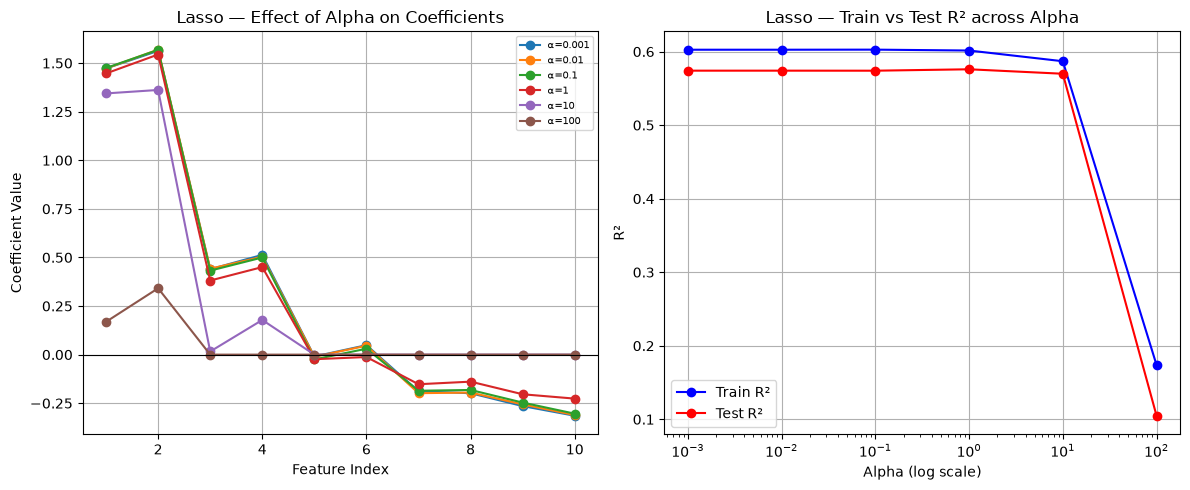

In [13]:
# Plot 1 — Effect of alpha on coefficients
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
all_weights = []

for alpha in alphas:
    lasso = LassoRegressionGD(
        learning_rate=0.01,
        epochs=1000,
        alpha=alpha,
        verbose=False
    )
    lasso.fit(X_train_poly_scaled, y_train_p)
    all_weights.append(lasso.weights.flatten())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for i, weights in enumerate(all_weights):
    plt.plot(range(1, 11), weights, marker='o', label=f'α={alphas[i]}')
plt.xlabel('Feature Index')
plt.ylabel('Coefficient Value')
plt.title('Lasso — Effect of Alpha on Coefficients')
plt.legend(fontsize=7)
plt.grid(True)
plt.axhline(y=0, color='black', linewidth=0.8)

# Plot 2 — Train vs Test R² across alphas
train_r2s = []
test_r2s = []

for alpha in alphas:
    lasso = LassoRegressionGD(
        learning_rate=0.01,
        epochs=1000,
        alpha=alpha,
        verbose=False
    )
    lasso.fit(X_train_poly_scaled, y_train_p)
    train_r2s.append(lasso.score(X_train_poly_scaled, y_train_p))
    test_r2s.append(lasso.score(X_test_poly_scaled, y_test_p))

plt.subplot(1, 2, 2)
plt.semilogx(alphas, train_r2s, 'b-o', label='Train R²')
plt.semilogx(alphas, test_r2s, 'r-o', label='Test R²')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R²')
plt.title('Lasso — Train vs Test R² across Alpha')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

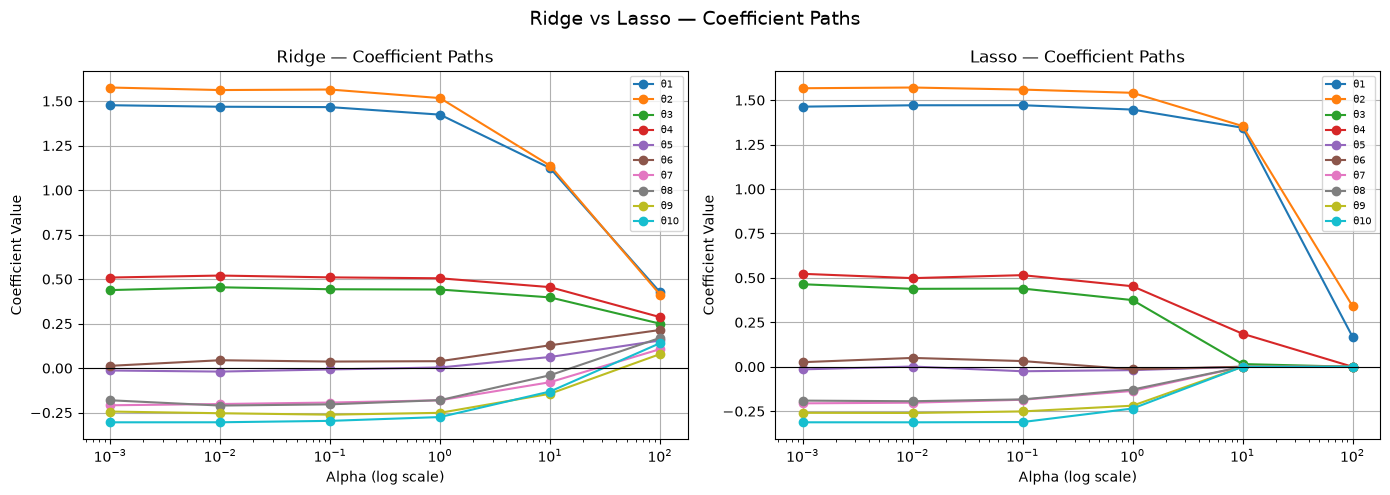

In [14]:
# Compare Ridge vs Lasso vs Linear Regression
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_weights = []
lasso_weights = []

for alpha in alphas:
    # Ridge
    ridge = RidgeRegressionGD(learning_rate=0.01, epochs=1000, alpha=alpha, verbose=False)
    ridge.fit(X_train_poly_scaled, y_train_p)
    ridge_weights.append(ridge.weights.flatten())
    
    # Lasso
    lasso = LassoRegressionGD(learning_rate=0.01, epochs=1000, alpha=alpha, verbose=False)
    lasso.fit(X_train_poly_scaled, y_train_p)
    lasso_weights.append(lasso.weights.flatten())

# Plot coefficient paths
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i in range(10):
    axes[0].plot(alphas, [w[i] for w in ridge_weights], marker='o', label=f'θ{i+1}')
    axes[1].plot(alphas, [w[i] for w in lasso_weights], marker='o', label=f'θ{i+1}')

axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)')
axes[0].set_ylabel('Coefficient Value')
axes[0].set_title('Ridge — Coefficient Paths')
axes[0].axhline(y=0, color='black', linewidth=0.8)
axes[0].legend(fontsize=7)
axes[0].grid(True)

axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('Coefficient Value')
axes[1].set_title('Lasso — Coefficient Paths')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].legend(fontsize=7)
axes[1].grid(True)

plt.suptitle('Ridge vs Lasso — Coefficient Paths', fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.linear_model import Ridge, Lasso

# Sklearn Ridge
sk_ridge = Ridge(alpha=10)
sk_ridge.fit(X_train_poly_scaled, y_train_p)


# Sklearn Lasso
sk_lasso = Lasso(alpha=0.1)
sk_lasso.fit(X_train_poly_scaled, y_train_p)

print("=" * 60)
print("SKLearn vs Scratch Comparison")
print("=" * 60)

# Ridge comparison
our_ridge = RidgeRegressionGD(learning_rate=0.01, epochs=1000, alpha=10, verbose=False)
our_ridge.fit(X_train_poly_scaled, y_train_p)

print("RIDGE (alpha=10):")
print(f"  Sklearn  → Train R²: {sk_ridge.score(X_train_poly_scaled, y_train_p):.4f} | Test R²: {sk_ridge.score(X_test_poly_scaled, y_test_p):.4f}")
print(f"  Scratch  → Train R²: {our_ridge.score(X_train_poly_scaled, y_train_p):.4f} | Test R²: {our_ridge.score(X_test_poly_scaled, y_test_p):.4f}")

print()

# Lasso comparison
our_lasso = LassoRegressionGD(learning_rate=0.01, epochs=1000, alpha=10, verbose=False)
our_lasso.fit(X_train_poly_scaled, y_train_p)

print("LASSO (alpha=0.1):")
print(f"  Sklearn  → Train R²: {sk_lasso.score(X_train_poly_scaled, y_train_p):.4f} | Test R²: {sk_lasso.score(X_test_poly_scaled, y_test_p):.4f}")
print(f"  Scratch  → Train R²: {our_lasso.score(X_train_poly_scaled, y_train_p):.4f} | Test R²: {our_lasso.score(X_test_poly_scaled, y_test_p):.4f}")

print()
print("Sklearn Lasso zero coefficients:", np.sum(sk_lasso.coef_ == 0), "/10")
print("Scratch Lasso zero coefficients:", np.sum(np.abs(our_lasso.weights.flatten()== 0) ), "/10")


SKLearn vs Scratch Comparison
RIDGE (alpha=10):
  Sklearn  → Train R²: 0.5843 | Test R²: 0.5772
  Scratch  → Train R²: 0.5818 | Test R²: 0.5765

LASSO (alpha=0.1):
  Sklearn  → Train R²: 0.5958 | Test R²: 0.5705
  Scratch  → Train R²: 0.5867 | Test R²: 0.5699

Sklearn Lasso zero coefficients: 8 /10
Scratch Lasso zero coefficients: 6 /10


### Why Our Scratch Needs Higher Alpha Than Sklearn

Sklearn’s `Lasso` uses **coordinate descent** — a more efficient algorithm that updates one weight at a time and finds the exact zero crossing. Our gradient-based soft-thresholding needs a larger threshold to kill weights because each update is smaller.

This is an important real-world lesson — **algorithm choice matters**. Same mathematical objective, different optimization algorithms, different behavior at the same alpha value.

In [21]:
from sklearn.linear_model import ElasticNet

elastic = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic.fit(X_train_poly_scaled, y_train_p)

print(f"ElasticNet Train R²: {elastic.score(X_train_poly_scaled, y_train_p):.4f}")
print(f"ElasticNet Test R²:  {elastic.score(X_test_poly_scaled, y_test_p):.4f}")
print(f"Zero coefficients:   {np.sum(elastic.coef_ == 0)}/10")
print(f"Coefficients: {elastic.coef_.round(4)}")

ElasticNet Train R²: 0.5939
ElasticNet Test R²:  0.5705
Zero coefficients:   7/10
Coefficients: [ 1.4134  1.5595  0.      0.0212  0.      0.     -0.      0.     -0.
 -0.    ]


## Regularization — Ridge and Lasso

Regularization prevents overfitting by adding a penalty term 
to the cost function that discourages large coefficients.

### Why Regularization?
- High degree polynomial models memorize training noise
- Large coefficients → model too sensitive to small input changes
- Regularization forces model to stay simple

### Ridge (L2)
Cost = MSE + α × Σθᵢ²

- Penalizes squared coefficients
- Shrinks all coefficients toward zero
- Never eliminates features completely
- Use when all features are potentially useful

### Lasso (L1)
Cost = MSE + α × Σ|θᵢ|

- Penalizes absolute values of coefficients
- Can shrink coefficients to exactly zero
- Performs automatic feature selection
- Use when you suspect many features are irrelevant

### Soft-Thresholding (Lasso)
Lasso uses proximal gradient descent — two separate steps:
1. Regular gradient step (reduce MSE)
2. Soft-threshold (apply L1 penalty — kill small weights)

threshold = learning_rate × alpha / m
new_weight = sign(w_temp) × max(|w_temp| - threshold, 0)

### Alpha — Regularization Strength
| Alpha | Effect |
|---|---|
| Too small | No regularization — same as Linear Regression |
| Just right | Balanced — good generalization |
| Too large | Underfitting — model too simple |

### Ridge vs Lasso
| | Ridge | Lasso |
|---|---|---|
| Penalty | L2 (squared) | L1 (absolute) |
| Coefficients | Shrink toward zero | Can reach exactly zero |
| Feature selection | No | Yes |
| When to use | All features useful | Many irrelevant features |

### ElasticNet
Combines both Ridge and Lasso:
Cost = MSE + α × (ρ × Σ|θ| + (1-ρ) × Σθ²)
Use when you want both shrinkage and feature selection.